<a href="https://colab.research.google.com/github/Vandana-kannan/Cat-Dog-Image-Classification-CNN/blob/main/vgg16_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
path = kagglehub.dataset_download("andrewtoh78/cats-and-dogs-dataset")

100%|██████████| 86.7M/86.7M [00:00<00:00, 98.9MB/s]

Extracting files...


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow import keras


In [3]:
import os

print(os.listdir(path))



['cats_and_dogs_small']


In [4]:
for root, dirs, files in os.walk(path):
    print(root, "Number of images:", len(files))

/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1 Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/test Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/test/dogs Number of images: 500
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/test/cats Number of images: 500
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation Number of images: 0
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation/dogs Number of images: 500
/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation/cats Number of images: 500
/root/.c

In [6]:

import os

# Base directory
base_dir = "/root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small"

# Training directory
train_dir = os.path.join(base_dir, "train")

# Validation directory
validation_dir = os.path.join(base_dir, "validation")

# Testing directory
test_dir = os.path.join(base_dir, "test")

# Display paths
print("Train directory:", train_dir)
print("Validation directory:", validation_dir)
print("Test directory:", test_dir)


Train directory: /root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/train
Validation directory: /root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/validation
Test directory: /root/.cache/kagglehub/datasets/andrewtoh78/cats-and-dogs-dataset/versions/1/cats_and_dogs_small/test


In [7]:
import os

print(os.path.exists(train_dir))
print(os.path.exists(validation_dir))
print(os.path.exists(test_dir))

True
True
True


In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [9]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)


In [10]:
train_generator= train_datagen.flow_from_directory(
    train_dir,
    batch_size=20,
    target_size=(150,150),
    class_mode="binary"
)

Found 2000 images belonging to 2 classes.


In [11]:
validation_generator= test_datagen.flow_from_directory(
    test_dir,
    batch_size=20,
    target_size=(150,150),
    class_mode="binary"
)

Found 1000 images belonging to 2 classes.


In [12]:
from tensorflow.keras import layers
from tensorflow.keras import models

In [13]:
from tensorflow.keras.applications import VGG16
conv_base=VGG16(weights="imagenet",
                include_top=False,
                input_shape=(150,150,3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model=models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256,activation='relu'))
model.add(layers.Dense(1,activation='sigmoid'))


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 16,812,353 (64.13 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
from tensorflow.keras import optimizers

In [19]:
model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.RMSprop(learning_rate=1e-4),
    metrics=['acc']
    )

In [24]:

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath="CNN-project-model-vgg16-{epoch:02d}.h5",
    save_best_only=True,
    monitor="val_loss",
    mode="min"
)


In [25]:
history=model.fit(
    train_generator,
    steps_per_epoch=10,
    epochs=5,
    validation_data=validation_generator,
    validation_steps=10
)

Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - acc: 0.4650 - loss: 0.9961 - val_acc: 0.6450 - val_loss: 0.6836
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - acc: 0.4700 - loss: 0.7307 - val_acc: 0.5050 - val_loss: 0.6923
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 325ms/step - acc: 0.4900 - loss: 0.7013 - val_acc: 0.4750 - val_loss: 0.6902
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 339ms/step - acc: 0.5000 - loss: 0.6978 - val_acc: 0.6000 - val_loss: 0.6765
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 518ms/step - acc: 0.6350 - loss: 0.6767 - val_acc: 0.5150 - val_loss: 0.6920


In [27]:

import pandas as pd

# Convert training history into DataFrame
hist_df = pd.DataFrame(history.history)

# CSV file name
hist_csv_file = "history.csv"

# Save history into CSV
with open(hist_csv_file, mode="w") as f:
    hist_df.to_csv(f, index=False)

print("Training history saved successfully!")


Training history saved successfully!


In [29]:
test_generator= test_datagen.flow_from_directory(
    test_dir,
    target_size=(150,150),
                 batch_size=20,
                 class_mode="binary")


Found 1000 images belonging to 2 classes.


In [31]:
model.evaluate(test_generator,steps=50)

50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - acc: 0.5380 - loss: 0.6808


[0.6807925701141357, 0.5379999876022339]

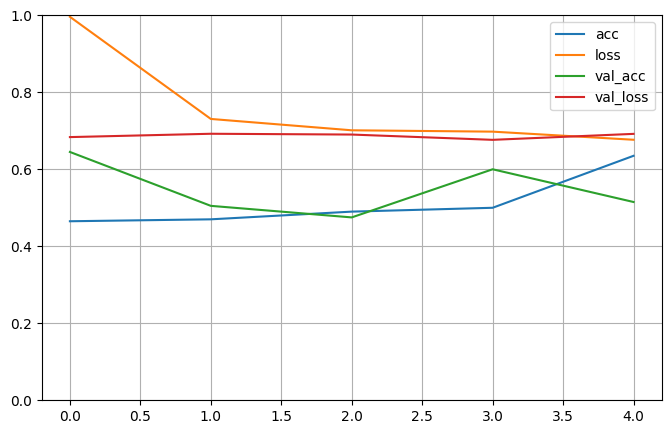

In [32]:
pd.DataFrame(history.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,1)
plt.show()